# P2 — Analyse des vélos en libre-service (CityBikes, 12 villes)

**Source** : couche silver `silver/velos/` (Parquet dans Silo) — **48,6 M lignes station × heure UTC**,
3 993 stations, de novembre 2024 à septembre 2026 (19 à 23 mois selon la ville).

**Indicateurs** (définis au Transform) : `activite` = nombre de mouvements dans l'heure (emprunts + retours,
somme des |Δ vélos|) ; `taux_remplissage` = vélos / (vélos + bornes libres) ; `est_vide`, `est_pleine`.
**Heures de pointe** : jours ouvrés, 7 h-10 h et 17 h-20 h (heure locale).

**Méthode « map → reduce »** : le silver est trop gros pour la mémoire ; chaque fichier (ville × mois) est réduit à
des sommes et comptages, puis les agrégats sont additionnés (`p2_velos/analytics.py`).

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from common.storage import get_storage
from common.silver import read_table
from common.config import load_villes
from common import viz
from p2_velos import analytics as a

viz.apply_style()
pd.set_option("display.width", 160)
s = get_storage()
agg = a.load_aggregates(s, read_table)                       # ~ 1 min : 263 fichiers lus et réduits
ind = a.station_indicators(agg, read_table(s, "silver/velos/stations.parquet"), load_villes())
print("Stations observées ≥ 30 jours :", len(ind), "→", ind["statut_station"].value_counts().to_dict())
display(ind[ind["statut_station"] != "exploitable"][["statut_station", "ville_id", "station_nom", "activite_jour", "pct_vide"]]
        .round(1).sort_values(["statut_station", "ville_id"]).reset_index(drop=True))
u = a.usable(ind)

Stations observées ≥ 30 jours : 3865 → {'exploitable': 3843, 'inactive': 15, 'technique': 7}


,statut_station,ville_id,station_nom,activite_jour,pct_vide
0,inactive,lille,Rue Corneille,0.0,100.0
1,inactive,lille,Place Spriet,0.0,100.0
2,inactive,lille,Motte Bossut,0.0,100.0
3,inactive,lille,Wattrelos Place,0.0,100.0
4,inactive,lille,Stalingrad,0.0,100.0
5,inactive,lille,Rue de Tourcoing,0.0,100.0
6,inactive,lille,Pellart,0.0,100.0
7,inactive,lille,Les Gobelins,0.0,100.0
8,inactive,lille,Laënnec,0.0,97.0
9,inactive,lille,Rue Louise Michel,0.0,100.0


**Contrôle qualité des stations** avant toute analyse (règles explicites, rien n'est retiré en silence) :
- **technique** : nom vide, borne « TEST » ou atelier de maintenance — dont une « station » sans nom à Lyon
  affichant ~8 000 mouvements par jour (15 fois la vraie station la plus active : un point technique, pas une borne) ;
- **aberrante** : plus de 50 mouvements par jour et par place (pour une capacité crédible ≥ 5 places) ;
- **inactive** : moins d'un mouvement par jour et vide 99,8 % du temps → **hors service** (14 à Lille, 1 à Paris).
  Elles sont exclues des classements mais signalées : c'est une information utile pour l'exploitant.

Les analyses portent sur les **stations exploitables**.

## Q1 — Stations au plus fort taux d'utilisation

**Méthode** : activité moyenne par jour = mouvements / jours observés. On compare aussi les villes (activité moyenne
par station) et la **concentration** : part de l'activité portée par les 10 % de stations les plus actives.

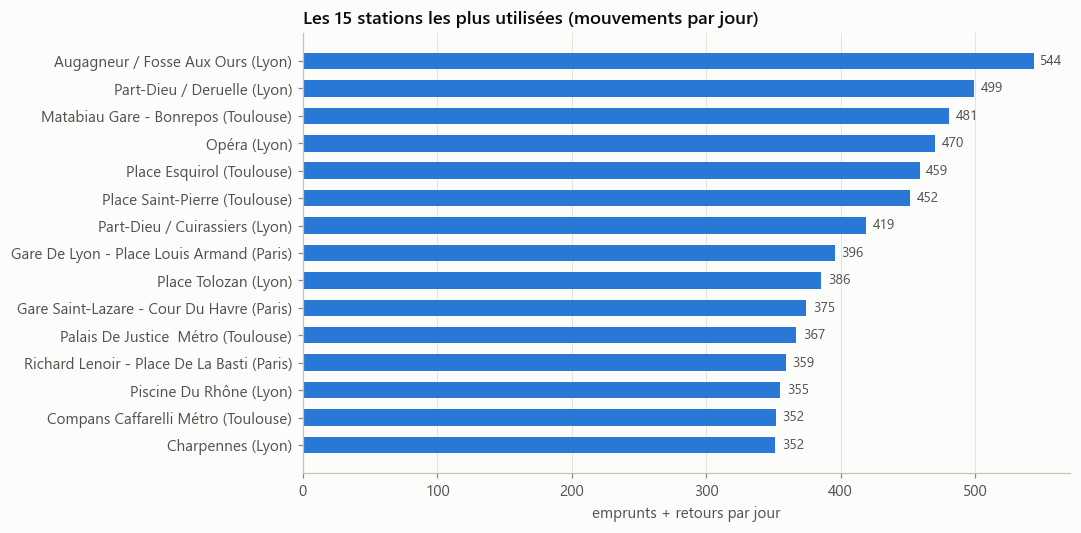

,ville_id,stations,activite_jour_station,part_top10pct
0,lyon,492,144.0,21.8
1,paris,1540,121.6,19.8
2,toulouse,455,115.7,24.4
3,marseille,248,110.3,21.9
4,lille,277,59.1,33.2
5,bordeaux,235,54.9,27.4
6,nantes,187,53.8,24.0
7,clermont-ferrand,90,51.4,27.1
8,rouen,136,41.2,29.4
9,rennes,81,39.5,22.1


In [2]:
top = a.top_stations(u, 15)
fig, ax = plt.subplots(figsize=(9, 5.2))
lab = (top["station_nom"].str.title().str.slice(0, 34) + " (" + top["ville_id"].str.title() + ")")[::-1]
ax.barh(lab, top["activite_jour"][::-1], color=viz.BLUE, height=0.6)
for y, v in enumerate(top["activite_jour"][::-1]):
    ax.text(v + 5, y, f"{v:.0f}", va="center", fontsize=9, color=viz.INK_2)
ax.set_title("Les 15 stations les plus utilisées (mouvements par jour)")
ax.set_xlabel("emprunts + retours par jour"); ax.grid(axis="y", visible=False)
plt.show()
conc = a.concentration(u)
display(conc)

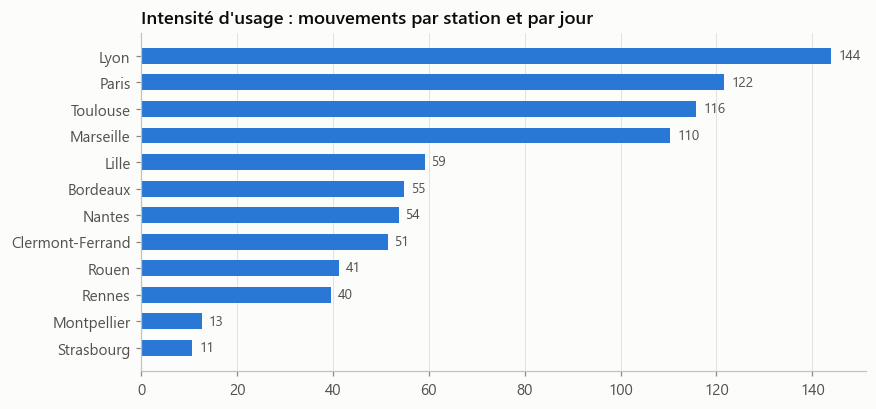

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 4))
c = conc.sort_values("activite_jour_station")
ax.barh(c["ville_id"].str.title(), c["activite_jour_station"], color=viz.BLUE, height=0.6)
for y, v in enumerate(c["activite_jour_station"]):
    ax.text(v + 1.5, y, f"{v:.0f}", va="center", fontsize=9, color=viz.INK_2)
ax.set_title("Intensité d'usage : mouvements par station et par jour"); ax.grid(axis="y", visible=False)
plt.show()

**Conclusion Q1.**
- Les stations les plus utilisées sont des **nœuds de transport et des places centrales** : Augagneur / Fosse aux
  Ours (544 mouvements/jour), Part-Dieu et Opéra à **Lyon**, la gare **Matabiau**, Esquirol et Saint-Pierre à
  **Toulouse**, la **gare de Lyon** (396) et la **gare Saint-Lazare** (375) à Paris — toutes à moins de 3 km du centre.
- **Lyon** a l'usage le plus intense (≈ 144 mouvements par station et par jour), devant Paris (122), Toulouse (116)
  et Marseille (110). **Montpellier (13) et Strasbourg (11)** sont très en retrait : petits réseaux, et Vélhop
  (Strasbourg) est surtout un service de location longue durée.
- L'usage est **concentré** : les 10 % de stations les plus actives portent 20 à 33 % des mouvements (un tiers à
  Lille et Strasbourg).

## Q2 — Zones où l'offre de vélos est insuffisante

**Méthode** : on découpe chaque ville en **zones carrées d'environ 500 m** et on calcule la **part du temps où les
stations de la zone sont vides** (pondérée par les heures observées). Une zone est dite **en sous-offre** si ses
stations sont vides **au moins 15 % du temps**.

2181 zones de ~500 m ; 255 en sous-offre (≥ 15 % du temps vides), 47 sévères (≥ 25 %)


,zones,sous_offre,pct_zones_sous_offre
ville_id,,,
marseille,160,78,48.8
lyon,260,63,24.2
clermont-ferrand,62,14,22.6
toulouse,274,53,19.3
rouen,83,14,16.9
nantes,74,6,8.1
lille,193,9,4.7
paris,788,16,2.0
bordeaux,157,2,1.3


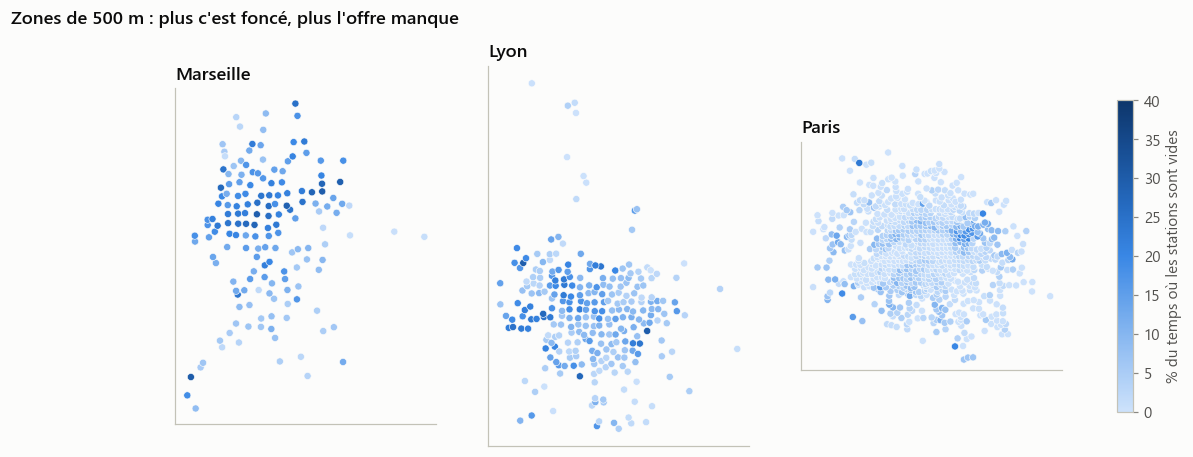

In [4]:
cells = a.grid_cells(u)
share = cells.groupby("ville_id").agg(zones=("pct_vide", "size"),
                                      sous_offre=("pct_vide", lambda x: (x >= 15).sum()))
share["pct_zones_sous_offre"] = (100 * share["sous_offre"] / share["zones"]).round(1)
print(f"{len(cells)} zones de ~500 m ; {(cells['pct_vide'] >= 15).sum()} en sous-offre (≥ 15 % du temps vides), "
      f"{(cells['pct_vide'] >= 25).sum()} sévères (≥ 25 %)")
display(share.sort_values("pct_zones_sous_offre", ascending=False))
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
for ax, ville in zip(axes, ["marseille", "lyon", "paris"]):
    g = cells[cells["ville_id"] == ville]
    sc = ax.scatter(g["longitude"], g["latitude"], c=g["pct_vide"].clip(upper=40), cmap=viz.SEQUENTIAL,
                    vmin=0, vmax=40, s=22, edgecolors=viz.SURFACE, linewidths=0.4)
    ax.set_title(ville.title()); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.set_aspect(1 / np.cos(np.radians(g["latitude"].mean())))
fig.colorbar(sc, ax=axes, shrink=0.8, label="% du temps où les stations sont vides")
fig.suptitle("Zones de 500 m : plus c'est foncé, plus l'offre manque", x=0.01, ha="left", fontweight="semibold")
plt.show()

**Conclusion Q2.**
- Sur environ 2 200 zones de 500 m, **un peu plus de 10 % sont en sous-offre** (stations vides ≥ 15 % du temps),
  dont une cinquantaine en sous-offre sévère (≥ 25 %).
- Le problème est très inégal : **Marseille** (près de la moitié de ses zones), puis **Lyon, Clermont-Ferrand,
  Toulouse et Rouen** (17 à 25 %) ; à l'inverse, **Paris (≈ 2 %), Bordeaux, Rennes, Montpellier et Strasbourg** sont
  quasi épargnés.
- La sous-offre touche surtout les **zones proches du centre**, là où la demande est forte : distance médiane au
  centre de **2,2 km à Marseille et 2,6 km à Lyon** pour les zones en sous-offre, contre 4,5 et 3,9 km pour les
  autres. À Lyon, un quart d'entre elles sont sur les **pentes de la Croix-Rousse** (relief).
- À Marseille, la sous-offre est cohérente avec un **taux de remplissage moyen très bas (0,24)** : le parc de vélos
  est petit par rapport au nombre de bornes.

## Q3 — Pics d'utilisation journaliers

**Méthode** : activité moyenne **par station et par heure**, selon l'heure locale et le jour de la semaine. Pour que
Paris (1 500 stations) n'écrase pas les autres villes, le profil de chaque ville est d'abord **normalisé** (divisé
par sa moyenne), puis on fait la moyenne des 12 profils.

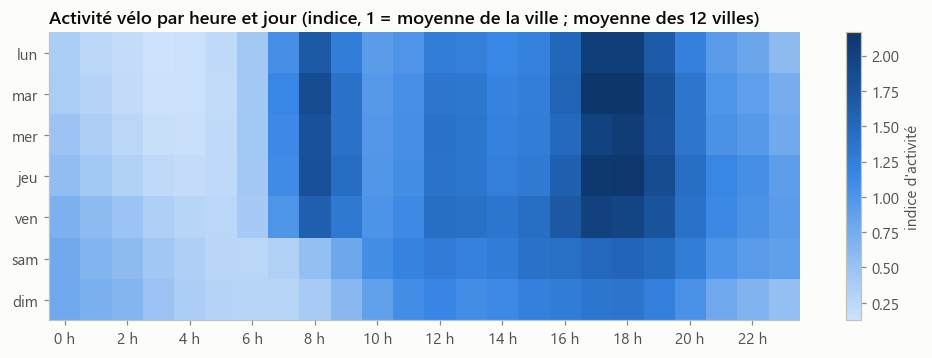

,ville_id,pic_matin_h,pic_soir_h,pic_weekend_h,ratio_pic_creux,ratio_semaine_weekend
0,bordeaux,8,17,18,14.0,1.33
1,clermont-ferrand,8,17,18,16.6,1.75
2,lille,8,18,18,22.9,1.40
3,lyon,8,18,18,14.0,1.28
4,marseille,8,17,18,8.8,1.12
5,montpellier,8,17,18,3.1,0.96
6,nantes,8,17,18,10.6,1.60
7,paris,8,18,18,12.0,1.12
8,rennes,8,18,18,4.5,1.11
9,rouen,8,17,18,10.3,1.20


In [5]:
w = a.weekly_profile(agg)
w["indice"] = w["activite_station_h"] / w.groupby("ville_id")["activite_station_h"].transform("mean")
hm = w.groupby(["wd", "h"])["indice"].mean().unstack("h")
fig, ax = plt.subplots(figsize=(11, 3.4))
im = ax.imshow(hm.values, cmap=viz.SEQUENTIAL, aspect="auto")
ax.set_yticks(range(7), ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"])
ax.set_xticks(range(0, 24, 2), [f"{h} h" for h in range(0, 24, 2)]); ax.grid(False)
ax.set_title("Activité vélo par heure et jour (indice, 1 = moyenne de la ville ; moyenne des 12 villes)")
fig.colorbar(im, ax=ax, label="indice d'activité"); plt.show()
display(a.peak_hours(w))

**Conclusion Q3.**
- **Les 12 villes ont le même rythme** : un pic à **8 h** et un pic plus fort à **17-18 h** les jours ouvrés —
  la signature des **trajets domicile-travail**. Le week-end, il n'y a qu'un pic, en fin d'après-midi (18 h).
- Au pic, l'activité est **10 à 23 fois** celle du creux de la nuit (2 h-5 h) ; le contraste est maximal à Lille.
- Les villes les plus « pendulaires » ont beaucoup plus d'activité en semaine qu'en week-end
  (**Clermont-Ferrand × 1,75, Nantes × 1,6**) ; à **Montpellier et Strasbourg**, l'usage de week-end égale ou
  dépasse celui de la semaine : un usage plutôt **loisir**.

## Q4 — Déséquilibres géographiques

**Méthode** : taux de remplissage moyen des stations à la pointe du **matin** (7 h-10 h) et du **soir** (17 h-20 h),
par **distance au centre-ville**. Un écart matin / soir révèle un flux net de vélos entre zones.

,zone,stations,rempl_matin,rempl_soir
0,0-1 km,466,0.347,0.410
1,1-2 km,705,0.381,0.392
2,2-4 km,1201,0.352,0.328
3,4-8 km,1113,0.389,0.322
4,8-50 km,358,0.450,0.423


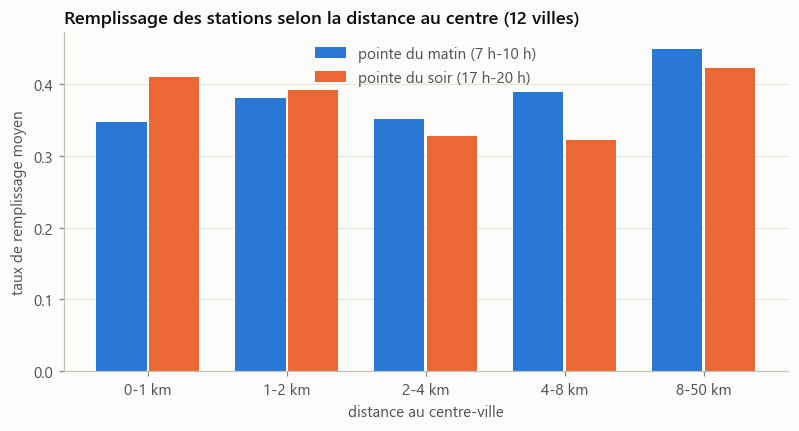

In [6]:
imb = a.imbalance_by_distance(u)
display(imb)
x = np.arange(len(imb))
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.bar(x - 0.19, imb["rempl_matin"], width=0.36, color=viz.BLUE, label="pointe du matin (7 h-10 h)")
ax.bar(x + 0.19, imb["rempl_soir"], width=0.36, color=viz.ORANGE, label="pointe du soir (17 h-20 h)")
ax.set_xticks(x, imb["zone"].astype(str)); ax.set_xlabel("distance au centre-ville")
ax.set_ylabel("taux de remplissage moyen"); ax.grid(axis="x", visible=False)
ax.set_title("Remplissage des stations selon la distance au centre (12 villes)"); ax.legend()
plt.show()

**Conclusion Q4.**
- Le **centre se remplit pendant la journée** : à moins d'1 km du centre, le remplissage passe de **0,35 le matin à
  0,41 le soir**, tandis qu'entre 4 et 8 km il **baisse de 0,39 à 0,32**. Les vélos « descendent » vers le centre le
  matin et n'en reviennent qu'en partie : c'est le **flux pendulaire** périphérie → centre.
- Au-delà de 8 km, les stations restent les plus pleines (≈ 0,45) : elles sont **sous-utilisées**.
- Conséquence pour l'exploitant : le rééquilibrage doit **ramener des vélos du centre vers la première couronne
  (2-8 km)** en fin de journée.

## Q5 — Stations critiques à rééquilibrer

**Méthode** : **score de criticité** = part des heures de pointe où la station est **vide** (impossible
d'emprunter) + part où elle est **pleine** (impossible de rendre). L'action recommandée dépend de la situation
dominante. Une station est dite **critique** si son score atteint 30 %.

,ville_id,station_nom,score_criticite,pct_vide_pointe,pct_pleine_pointe,action,activite_jour
0,paris,Damrémont - Caulaincourt,88.3,88.3,0.0,réapprovisionner,4.3
1,clermont-ferrand,60 - Parc de la Muraille,87.8,87.8,0.0,réapprovisionner,5.7
2,bordeaux,Ilots Quinconces,76.5,76.5,0.0,réapprovisionner,4.9
3,bordeaux,Ilot Hôtel de Ville,75.6,74.1,1.5,réapprovisionner,4.0
4,marseille,Jean Moulin - Saint Etienne,70.1,10.1,60.0,désengorger,159.6
5,lyon,TECHSUD,69.4,44.2,25.2,réapprovisionner,33.9
6,marseille,Foch - Fayolle,69.0,69.0,0.0,réapprovisionner,77.6
7,marseille,Paris - Forbin,66.5,66.5,0.0,réapprovisionner,53.2
8,bordeaux,Ilot Les Hangars,59.3,59.3,0.0,réapprovisionner,4.3
9,bordeaux,Ilot Victoire,52.5,51.8,0.7,réapprovisionner,6.2


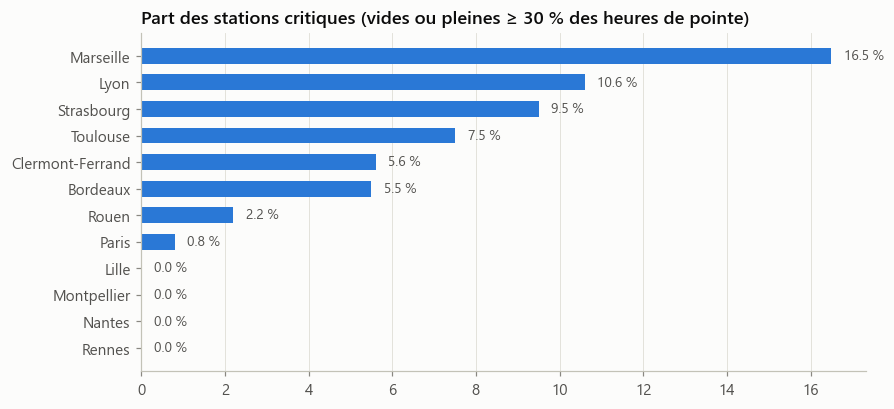

In [7]:
crit = a.critical_stations(u, 15)
display(crit)
cs = a.critical_share(u)
fig, ax = plt.subplots(figsize=(8.5, 4))
c = cs.sort_values("pct_critiques")
ax.barh(c["ville_id"].str.title(), c["pct_critiques"], color=viz.BLUE, height=0.6)
for y, v in enumerate(c["pct_critiques"]):
    ax.text(v + 0.3, y, f"{v:.1f} %", va="center", fontsize=9, color=viz.INK_2)
ax.set_title("Part des stations critiques (vides ou pleines ≥ 30 % des heures de pointe)")
ax.grid(axis="y", visible=False); plt.show()

**Conclusion Q5.**
- **Marseille (16,5 % de stations critiques) et Lyon (≈ 11 %)** ont le plus de stations à rééquilibrer ;
  **Paris (< 1 %)** se distingue par une régulation efficace malgré son volume, et **Lille, Nantes, Rennes,
  Montpellier** n'en ont aucune.
- La station la plus critique est **Damrémont - Caulaincourt (Paris)**, **vide 88 % des heures de pointe** : elle est
  au sommet de la butte Montmartre — les usagers la descendent à vélo mais ne la remontent pas (**effet relief**).
  Même logique pour le **Parc de la Muraille** à Clermont-Ferrand.
- La grande majorité des stations critiques sont **à réapprovisionner** (vides) ; quelques-unes sont **à
  désengorger** (pleines), comme **Jean Moulin - Saint-Étienne à Marseille**, pleine 60 % des heures de pointe.
- *Limite* : certaines stations critiques ont une faible activité (les « îlots » de Bordeaux) : elles sont souvent
  vides **parce qu'**elles sont peu alimentées — c'est justement le signal d'un besoin de réapprovisionnement.

## Synthèse P2

| Question | Réponse |
|---|---|
| Stations les plus utilisées | gares et places centrales (Lyon Part-Dieu / Opéra, Toulouse Matabiau, Paris gare de Lyon et Saint-Lazare) |
| Ville à l'usage le plus intense | Lyon (≈ 144 mouvements / station / jour) ; Strasbourg et Montpellier très en retrait |
| Sous-offre | ≈ 10 % des zones de 500 m ; Marseille très touchée, Paris presque pas |
| Pics | 8 h et 17-18 h dans les 12 villes (domicile-travail) ; 18 h le week-end |
| Déséquilibre | le centre se remplit dans la journée, la première couronne (2-8 km) se vide |
| Rééquilibrage prioritaire | Marseille et Lyon ; stations de hauteur (Montmartre) à réapprovisionner |

*Limites* : l'`activite` inclut les **rééquilibrages par camion** (visibles la nuit) ; 19 à 23 mois de données
seulement (archive CityBikes depuis novembre 2024) ; capacité déclarée parfois incohérente (Marseille) ; les stations
inactives et techniques sont exclues mais listées.